In [204]:
import warnings
import os 
from pathlib import Path

import pandas as pd
import scanpy as sc 
import numpy as np 
import scipy.sparse as sp
from dotenv import dotenv_values
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.ticker import FormatStrFormatter
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from collections import defaultdict
import zarr 
import seaborn as sns

from hm3d_utils.spatial import BoundingBox3D

warnings.simplefilter(action='ignore', category=FutureWarning)

In [205]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_02"
os.makedirs(OUTDIR, exist_ok=True)

SPATIAL_DIR = DATADIR / "7_spatial"

SC_REF_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad' # for descr mapper
ST_FP = DATADIR / "9_objects" / "spatial" / 'hypomap3d_spatial_cell_level.h5ad'
ST_VOXEL_FP = DATADIR / "9_objects" / "spatial" / 'hypomap3d_spatial_voxel_level.zarr'
COORD_FP = DATADIR / "11_brainrender" / "coord_space.csv"

MIN_HVG_COUNTS = 100

### Get mapper for cell types

In [206]:
def build_id_mapping(n_df, id_pattern, target_pattern, levels=range(1, 6),):
    mapping = {}

    # --- 1. from wide dataframe ---
    for i in levels:
        id_col = id_pattern.format(i=i)
        target_col = target_pattern.format(i=i)

        if id_col in n_df.columns and target_col in n_df.columns:
            mapping.update(
                n_df[[id_col, target_col]]
                .dropna()
                .drop_duplicates()
                .set_index(id_col)[target_col]
                .to_dict()
            )

    return mapping

In [207]:
adata_sc = sc.read_h5ad(SC_REF_FP, backed="r")

abclike_mapper = build_id_mapping(adata_sc.obs,
    id_pattern="L{i}_ID",
    target_pattern="L{i}_abc_like")

descr_mapper = build_id_mapping(adata_sc.obs,
    id_pattern="L{i}_ID",
    target_pattern="L{i}_descr") 


### Let's load the spatial data

In [45]:
openst = sc.read_h5ad(SPATIAL_DIR / "qc_figure_objects" / "SP2-03_no_qc_unbounded.h5ad")

### Let's propagate confidences up the levels 

In [46]:

def build_map_matrix(leaves_to_level):

    leaves_to_level = np.asarray(leaves_to_level)
    level_names, inv = np.unique(leaves_to_level, return_inverse=True)
    rows = inv
    cols = np.arange(len(leaves_to_level))
    data = np.ones(len(leaves_to_level), dtype=np.uint8)
    M = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(len(level_names), len(leaves_to_level)),
    ).tocsr()   

    return M, level_names 

def propagate_confidences(adata):
    pathmat = adata.uns["pathmat"]

    # split and keep first token
    pathmat_clean = np.vectorize(lambda x: x.split(" ")[0])(pathmat)

    adata.uns["pathmat"] = pathmat_clean

    pathmat = adata.uns["pathmat"]  # (n_leaves, 5)
    P_L5 = adata.obsm["P_path"] 

    # Build index maps

    level_maps = [] # 4 arrays indicating the cluster label of the path at Level i
    level_labels = {} # 4 keys, one for each level, mapping to arrays of unique cluster labels

    for lvl in range(4):
        labels = pathmat[:, lvl]
        level_labels[lvl] = np.unique(labels)
        level_maps.append(labels)

    # sum up 

    P_levels = {}

    for lvl in range(4):
        M, ids = build_map_matrix(level_maps[lvl])
        
        # (cells × leaves) @ (leaves × level_nodes)^T
        # Multiplying the cell × L5 probability matrix with M.T sums the
        # probabilities of all leaves belonging to the same parent cluster.
        P_lvl = P_L5 @ M.T
        
        P_levels[f"L{lvl+1}"] = P_lvl
        adata.uns[f"L{lvl+1}_ID"] = ids
        adata.uns[f"L{lvl+1}_descr"] = [descr_mapper[i] for i in ids]
        adata.uns[f"L{lvl+1}_abc_like"] = [abclike_mapper[i] for i in ids]
        adata.obsm[f"P_L{lvl+1}"] = P_lvl

    ids = adata.uns["pathmat"][:, 4]
    adata.uns[f"L5_ID"] = ids
    adata.uns[f"L5_descr"] = [descr_mapper[i] for i in ids]
    adata.uns[f"L5_abc_like"] = [abclike_mapper[i] for i in ids]
    adata.obsm[f"P_L5"] = P_L5

    for lvl in range(1, 6):
        P = adata.obsm[f"P_L{lvl}"]

        max_idx = np.asarray(P.argmax(axis=1)).ravel()
        max_prob = np.asarray(P.max(axis=1).toarray()).ravel()

        descr = np.asarray(adata.uns[f"L{lvl}_descr"])
        abc = np.asarray(adata.uns[f"L{lvl}_abc_like"])

        adata.obs[f"L{lvl}_descr_max_p"] = descr[max_idx]
        adata.obs[f"L{lvl}_abc_like_max_p"] = abc[max_idx]
        adata.obs[f"L{lvl}_max_p"] = max_prob


In [47]:
propagate_confidences(openst)

### Let's get indicators for what gets filtered due to HVGs and bbox (only required for OpenST)

In [48]:
openst.obs['total_counts'] = np.asarray(openst.X.sum(axis=1)).ravel()
openst.obs['total_hvg_counts'] = np.asarray(openst[:, openst.var['IsHVG']].X.sum(axis=1)).ravel()
openst.obs['total_genes'] = np.asarray((openst.X > 0).sum(axis=1)).ravel()

openst.obs["GetsHvgFiltered"] = openst.obs['total_hvg_counts'] < MIN_HVG_COUNTS

In [49]:
bbox_mm = BoundingBox3D.load(SPATIAL_DIR / "bounding_box_ccf_mm.json")

In [50]:
x_min, y_min, z_min = bbox_mm.min 
x_max, y_max, z_max = bbox_mm.max

xx = openst.obsm["coords_ccf_mm"].loc[:, "x"].values
yy = openst.obsm["coords_ccf_mm"].loc[:, "y"].values
zz = openst.obsm["coords_ccf_mm"].loc[:, "z"].values

inside_bbox_mask = (
    xx >= x_min) & (
    xx <= x_max) & (
    yy >= y_min) & (
    yy <= y_max) & (
    zz >= z_min) & (
    zz <= z_max
)

openst.obs["IsInsideBbox"] = inside_bbox_mask 

openst.obs["x_ccf"] = xx 
openst.obs["y_ccf"] = yy 
openst.obs["z_ccf"] = zz 

### OpenST QC metrics per cell 

In [264]:
# load raw data for additional metrics dropped in the pipeline 
openst_raw = sc.read_h5ad(SPATIAL_DIR / "raw" / "Bauder_spatial.h5ad", backed="r") 

In [265]:
metrics = ["total_counts", "n_genes_by_counts", "reads_per_counts"]
openst.obs[metrics] = openst_raw.obs[metrics].values

In [266]:
# Convert obs to DataFrame
df = openst.obs.copy()

# Ensure gets_filtered is boolean
df["GetsHvgFiltered"] = df["GetsHvgFiltered"].astype(bool)

df["x_ccf_str"] = df["x_ccf"].round(3).astype(str)

metrics = ["total_counts", "n_genes_by_counts", "reads_per_counts"]

x_var = "x_ccf_str"

# Prepare data for plotting
# One row per metric, x_ccf, and filtering status
long_df = []
for m in metrics:
    # All rows
    tmp_all = df[[x_var, m]].assign(Filter="All")
    tmp_all["Metric"] = m
    long_df.append(tmp_all)

    # Filtered rows only
    tmp_filt = df[df["GetsHvgFiltered"] == False][[x_var, m]].assign(Filter="Filtered")
    tmp_filt["Metric"] = m
    long_df.append(tmp_filt)

long_df = pd.concat(long_df, axis=0)



In [267]:
long_df.head(2)

,x_ccf_str,total_counts,Filter,Metric,n_genes_by_counts,reads_per_counts
SP2-03_fc_sts_079_2_1,6.018,3.0,All,total_counts,NaN,NaN
SP2-03_fc_sts_079_2_2,6.018,0.0,All,total_counts,NaN,NaN


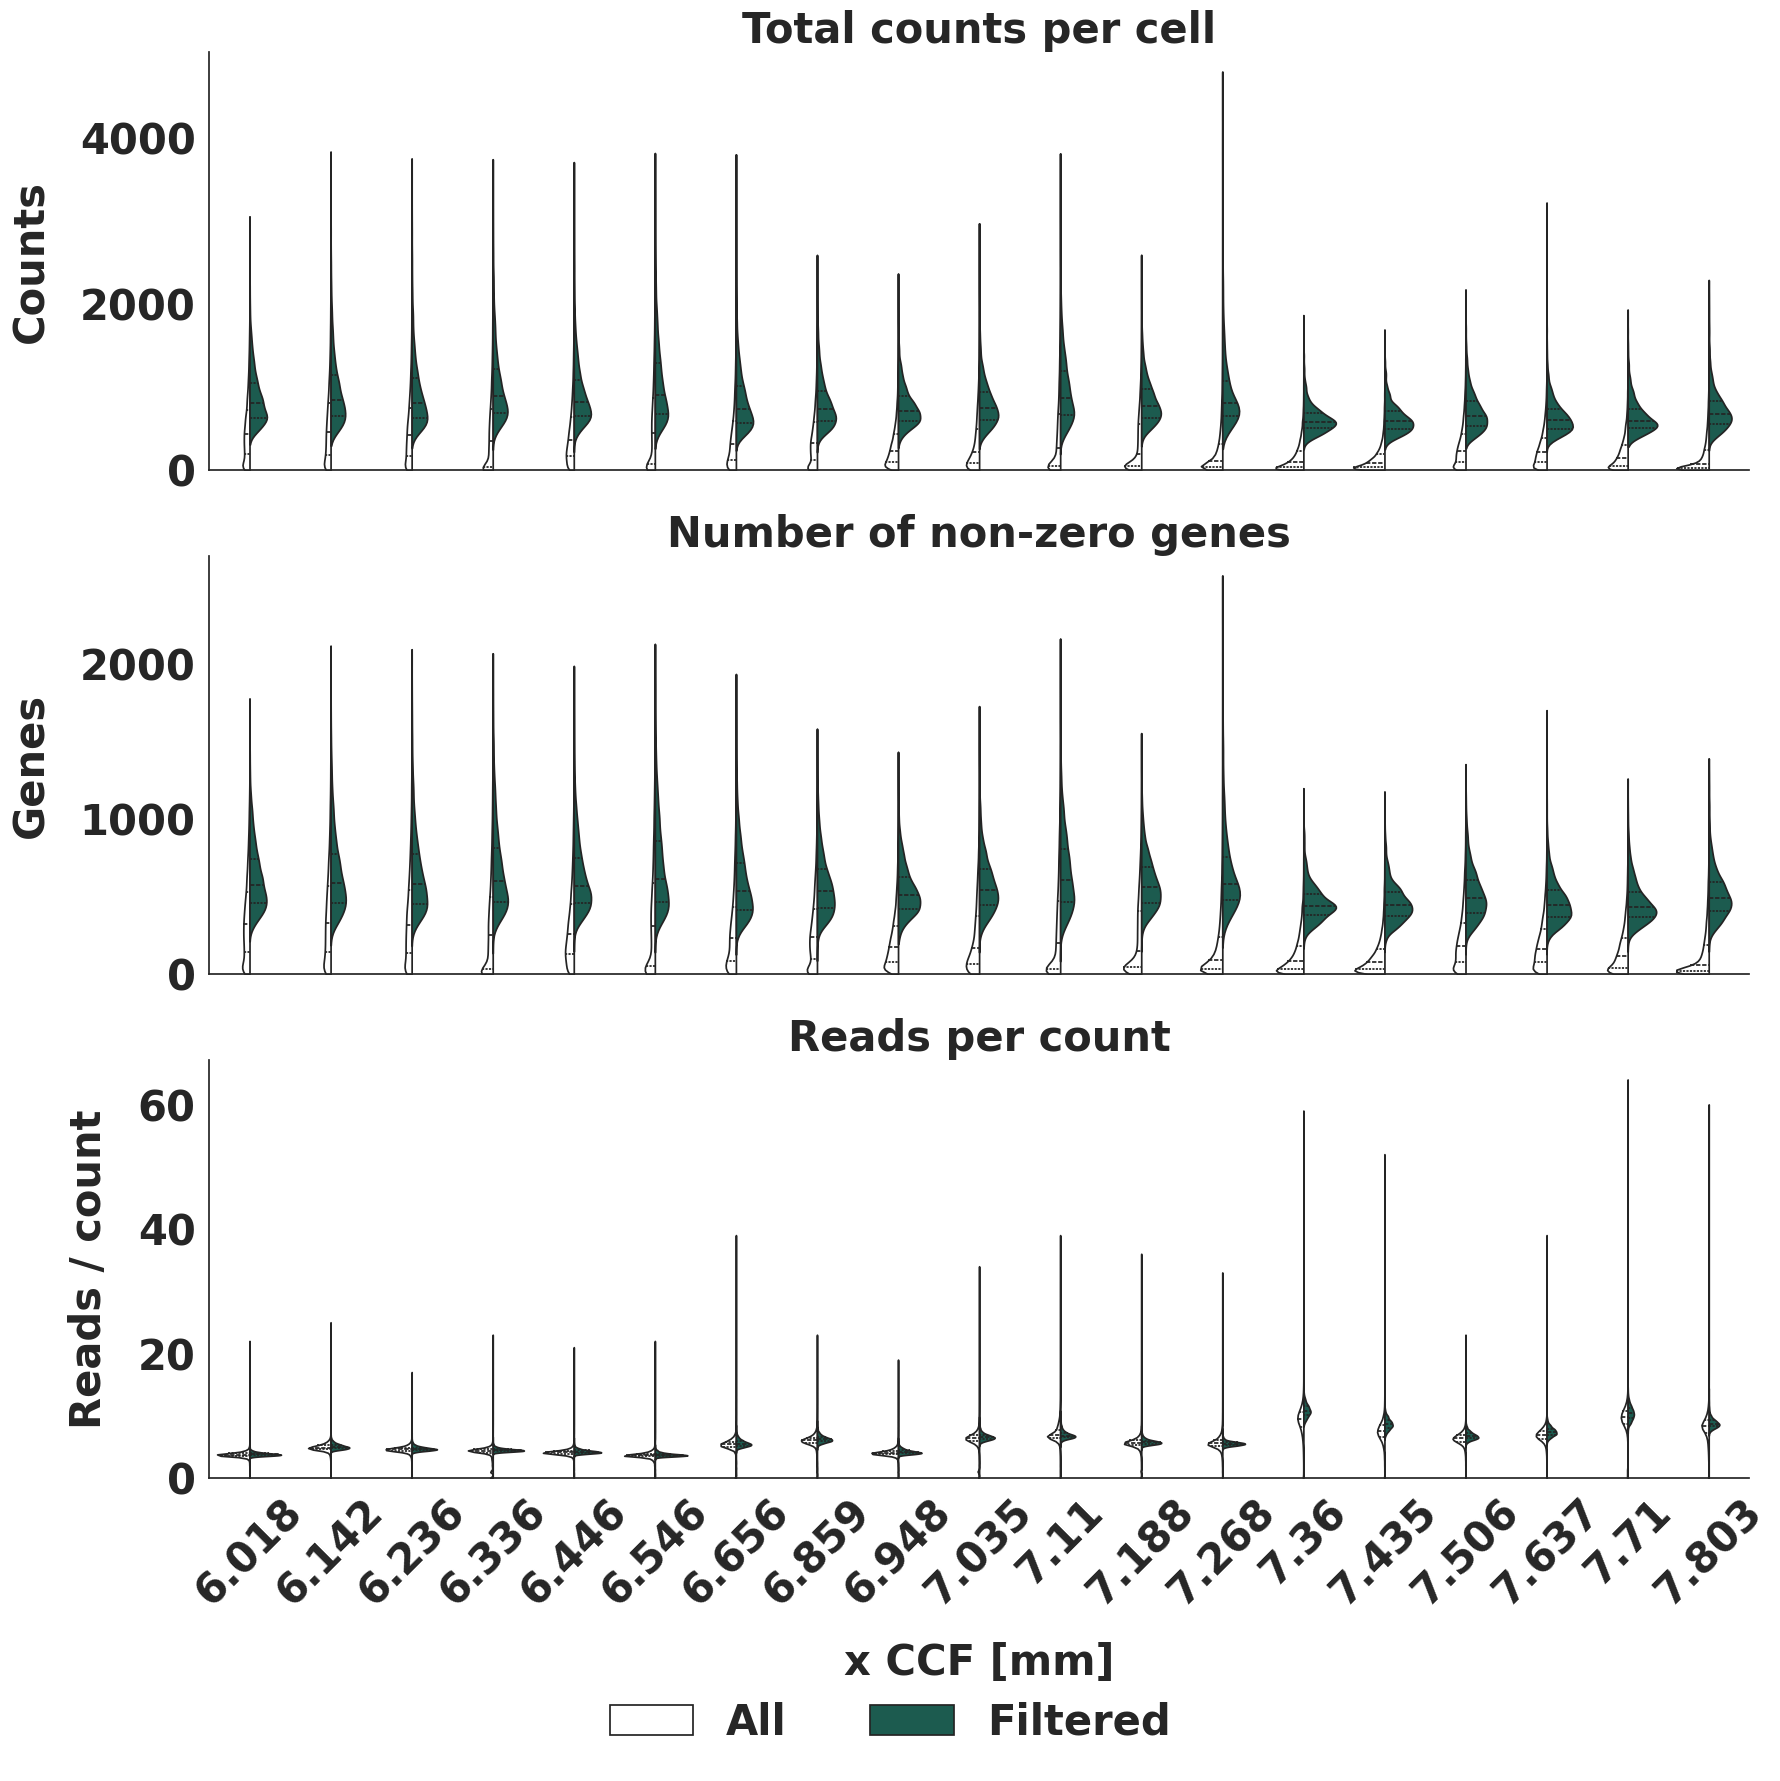

In [268]:
# Mapping for titles and y-labels
metric_labels = {
    "total_counts": {"title": "Total counts per cell", "ylabel": "Counts"},
    "n_genes_by_counts": {"title": "Number of non-zero genes", "ylabel": "Genes"},
    "reads_per_counts": {"title": "Reads per count", "ylabel": "Reads / count"},
}

# Style
labelsize = 30
violin_palette = {"All": "white", "Filtered": "#116656"}
sns.set(style="white")  # removes grid automatically
font_kwargs = {"fontsize": labelsize, "fontweight": "bold"}

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(18, 18), sharex=True)

# Plot each metric
handles = None
labels = None

for ax, metric in zip(axes, metrics):
    plot_df = long_df[long_df["Metric"] == metric].fillna(0)

    g = sns.violinplot(
        data=plot_df,
        x=x_var,
        y=metric,
        hue="Filter",
        ax=ax,
        cut=0,
        inner="quartile",
        split=True,
        palette=violin_palette
    )

    # Save legend handles only once
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_ylim(bottom=0)

    # Set custom title and ylabel from dictionary
    ax.set_title(metric_labels[metric]["title"], **font_kwargs)
    ax.set_ylabel(metric_labels[metric]["ylabel"], **font_kwargs, labelpad=20)
    ax.set_xlabel("x CCF [mm]", **font_kwargs, labelpad=20)

    # Bold tick text
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='both', labelsize=labelsize)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_fontweight("bold")

    # Remove subplot legend
    ax.get_legend().remove()

    sns.despine(ax=ax)

# Create a single legend below last plot
legend = fig.legend(
    handles, labels,
    loc="lower center",
    ncol=2,
    fontsize=labelsize,
    frameon=False
)
for text in legend.get_texts():
    text.set_fontweight("bold")

plt.tight_layout(rect=(0, 0.05, 1, 1))

plt.savefig(OUTDIR / "openst_focus_qc.pdf", dpi=300, format="pdf", bbox_inches='tight',)


plt.show()


## Comparing to other authors when these are restricted to OpenST's x range

For this we compare only the data that is in the final atlas.

In [208]:
adata_st = sc.read_h5ad(ST_FP, backed="r")

In [209]:
adata_st

AnnData object with n_obs × n_vars = 1401313 × 56939 backed at '/REDACTED-path/HypoMap3D_spatial_cell_level.h5ad'
    obs: 'Dataset', 'Sample', 'Author', 'Technology', 'Donor', 'Sex', 'RegionID', 'RegionAcronym', 'RegionName', 'total_counts', 'total_hvg_counts', 'total_genes', 'IsHY', 'L1_descr_max_p', 'L1_abc_like_max_p', 'L1_max_p', 'L2_descr_max_p', 'L2_abc_like_max_p', 'L2_max_p', 'L3_descr_max_p', 'L3_abc_like_max_p', 'L3_max_p', 'L4_descr_max_p', 'L4_abc_like_max_p', 'L4_max_p', 'L5_descr_max_p', 'L5_abc_like_max_p', 'L5_max_p'
    var: 'gene_stable_ids', 'IsHVG'
    uns: 'L1_ID', 'L1_abc_like', 'L1_descr', 'L2_ID', 'L2_abc_like', 'L2_descr', 'L3_ID', 'L3_abc_like', 'L3_descr', 'L4_ID', 'L4_abc_like', 'L4_descr', 'L5_ID', 'L5_abc_like', 'L5_descr', 'flags', 'pathmat'
    obsm: 'P_L1', 'P_L2', 'P_L3', 'P_L4', 'P_L5', 'X_embed', 'X_umap', 'X_umap_sc', 'coords_ccf_mm', 'coords_ccf_mm_wrap', 'coords_source', 'coords_voxels_25um', 'coords_voxels_25um_bounded'
    varm: 'IsCaptured'

In [210]:
openst_xccf_min = adata_st[adata_st.obs.Author == "Bauder"].obsm["coords_ccf_mm"].x.min()
openst_xccf_max = adata_st[adata_st.obs.Author == "Bauder"].obsm["coords_ccf_mm"].x.max()
openst_xccf_min, openst_xccf_max

(np.float64(6.018229007720947), np.float64(7.803075790405273))

In [211]:
openst_range_mask = (
    adata_st.obsm["coords_ccf_mm"].x >= openst_xccf_min) & (
    adata_st.obsm["coords_ccf_mm"].x <= openst_xccf_max
    )

adata_st = adata_st[openst_range_mask,:]

In [212]:
openstrange = adata_st.obs.copy()

In [213]:
openstrange.Author = openstrange.Author.replace({
                                        "Bauder": "OpenST"})

In [214]:
for i in range(2,6):
    openstrange[f"is_high_confidence_L{i}"] = openstrange[f"L{i}_max_p"] > 0.5

In [215]:

# Provided color palette
st_author_colors = {
    "Langlieb": "#b45f06",
    "Zhang": "#ad5d5d",
    "Yao": "#DDDED6",
    "OpenST": "#116656",
}


## compare availability of captured priority genes

In [216]:

#gene_meta_cols = ["IsMouseTF", "IsHumanTFOrtholog", "IsSourceGene", "IsTargetGene", "IsPriorityGene", "IsTopGene"]
gene_meta_cols = ["IsPriorityGene"]

capt_df = pd.concat([
    adata_st.varm["IsCaptured"],
    adata_sc.var.loc[adata_st.var.index, gene_meta_cols]
], axis=1)

capt_df = capt_df.rename(columns={"SP2-01": "Yao", "SP2-02": "Zhang", "SP2-03": "OpenST", "SP2-04": "Langlieb"})

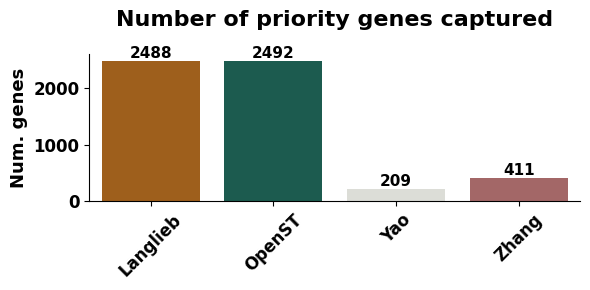

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ------------------------------------------------------------
# Define columns
# ------------------------------------------------------------

author_cols = [
    c for c in st_author_colors.keys()
    if c in capt_df.columns
]

annotation_cols = [
    c for c in capt_df.columns
    if c not in author_cols
]


# ------------------------------------------------------------
# Summarize captured genes per annotation
# ------------------------------------------------------------

plot_data = []

for annotation in annotation_cols:

    for author in author_cols:

        # genes captured by this author
        captured = capt_df[author]

        # among captured genes, count those with annotation
        n_annotation = (
            capt_df.loc[captured, annotation]
            .sum()
        )

        n_captured = captured.sum()

        plot_data.append(
            {
                "annotation": annotation,
                "author": author,
                "count": n_annotation,
                "fraction": n_annotation / n_captured if n_captured > 0 else 0,
            }
        )

plot_df = pd.DataFrame(plot_data)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

annotations = annotation_cols

fig, axes = plt.subplots(
    len(annotations),
    1,
    figsize=(6, 3 * len(annotations)),
    sharex=True,
)

if len(annotations) == 1:
    axes = [axes]


for ax, annotation in zip(axes, annotations):

    subset = plot_df.query(
        "annotation == @annotation"
    )

    sns.barplot(
        data=subset,
        x="author",
        y="count",
        order=sorted(author_cols),
        palette=st_author_colors,
        ax=ax,
    )

    for i, row in subset.iterrows():
        ax.text(
            list(sorted(author_cols)).index(row["author"]),
            row["count"],
            f"{int(row['count'])}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
        )

    # ax.set_title(
    #     annotation,
    #     fontsize=16,
    #     fontweight="bold",
    # )

    # ax.set_ylabel(
    #     f"Captured {annotation}s",
    #     fontsize=13,
    #     fontweight="bold",
    # )


    ax.set_title(
        "Number of priority genes captured",
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    ax.set_ylabel(
        f"Num. genes",
        fontsize=13,
        fontweight="bold",
    )

    ax.set_xlabel("")

    ax.tick_params(
        axis="both",
        labelsize=12,
    )

    for label in ax.get_xticklabels():
        label.set_rotation(45)
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    sns.despine(ax=ax)


plt.tight_layout()

plt.savefig(
    OUTDIR / "captured_gene_annotations.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## whole AP overview 

In [217]:
voxel_store = zarr.open(ST_VOXEL_FP, mode="r")

In [218]:
coords = pd.read_csv(COORD_FP)

coords.x_ccf /= 1000
coords.y_ccf /= 1000
coords.z_ccf /= 1000


In [219]:
def get_region_x_boundaries(voxel_store, coords, region_acronym):
    region_idx = list(voxel_store["region"]["acronyms"][...]).index(region_acronym)
    bin_mask = np.asarray(voxel_store["region"]["region_masks"][region_idx, ...]).reshape(-1)

    x_coords = coords.loc[bin_mask, "x_ccf"]
    return x_coords.min(), x_coords.max()


In [220]:
pvh_x_min, pvh_x_max = get_region_x_boundaries(voxel_store, coords, "PVH")
arh_x_min, arh_x_max = get_region_x_boundaries(voxel_store, coords, "ARH")
pvp_x_min, pvp_x_max = get_region_x_boundaries(voxel_store, coords, "PVp")
mpn_x_min, mpn_x_max = get_region_x_boundaries(voxel_store, coords, "MPN")
hy_x_min, hy_x_max = get_region_x_boundaries(voxel_store, coords, "HY")

In [221]:
pvh_x_min, pvh_x_max

(np.float64(5.675004959106445), np.float64(6.4250078201293945))

In [222]:
def add_region_arrow(x_start, x_end, label, y, color="black", x_shift = 0):
    plt.annotate(
        "",
        xy=(x_end, y),
        xytext=(x_start, y),
        arrowprops=dict(
            arrowstyle="<->",
            color=color,
            lw=3,
            shrinkA=0,
            shrinkB=0,
        ),
        zorder=20,
    )

    plt.text(
        (x_start+x_end)/2 + x_shift,
        y+0.05,
        label,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        color=color,
        zorder=20,
    )

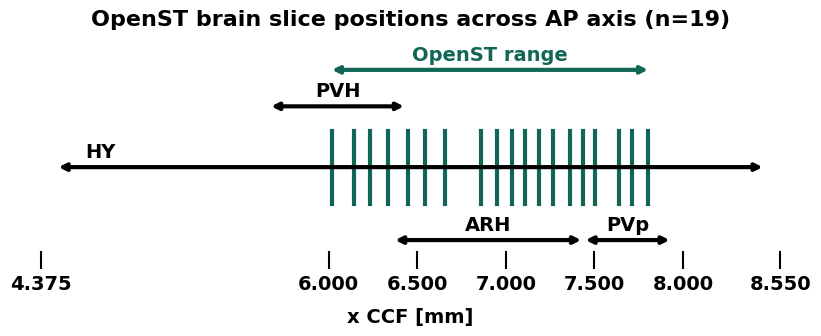

In [226]:
# Extract the unique x_ccf coordinates
x_coords = np.sort(openst.obs['x_ccf'].unique())
n_slices = len(x_coords)

# Create the figure
plt.figure(figsize=(10, 3))

# Define arrow range
play = 0.1
xmin, xmax = x_min - play, x_max + play

# Style adjustments
plt.ylim(-0.8, 1.1)
plt.xlim(xmin, xmax)  
plt.yticks([])

# Add region arrows
add_region_arrow(
    openst_xccf_min,
    openst_xccf_max,
    "OpenST range",
    y=0.8,
    color="#116656"
)

add_region_arrow(
    arh_x_min,
    arh_x_max,
    "ARH",
    y=-0.6,
    color="black"
)

add_region_arrow(
    pvh_x_min,
    pvh_x_max,
    "PVH",
    y=0.5,
    color="black"
)

add_region_arrow(
    hy_x_min,
    hy_x_max,
    "HY",
    y=0,
    color="black",
    x_shift= -1.75
)

add_region_arrow(
    pvp_x_min,
    pvp_x_max,
    "PVp",
    y=-0.6,
    color="black"
)

# Plot vertical lines at each x_ccf coordinate
for x in x_coords:
    plt.plot([x, x], [-0.3, 0.3], color='#116656', lw=3)



# Remove the last tick label if it exceeds xmax
xticks = plt.xticks()[0]
xticks = xticks[((xticks >= 6) & (xticks <= 8))]  # keep only ticks within arrow range
xticks = np.concatenate(([x_min], xticks, [x_max]))
xticks = np.unique(xticks)  # avoids duplicates if x_min or x_max are already ticks
plt.xticks(xticks)


# Add manual tick marks
for x in xticks:
    plt.plot(
        [x, x],
        [-0.8, -0.7],
        color="black",
        lw=1.5,
        zorder=5
    )

# Labels and title formatting
plt.xlabel("x CCF [mm]", fontsize=14, fontweight='bold', labelpad=10)
plt.title(f"OpenST brain slice positions across AP axis (n={n_slices})",
          fontsize=16, fontweight='bold')
plt.tick_params(axis='x', labelsize=14, width=1.5)
for label in plt.gca().get_xticklabels():
    label.set_fontweight('bold')
plt.box(False)

plt.savefig(OUTDIR / "openst_brainslice_positions_within_atlas.pdf", dpi=300, format="pdf", bbox_inches='tight',)

plt.show()

## % cells per author in OPENST Range

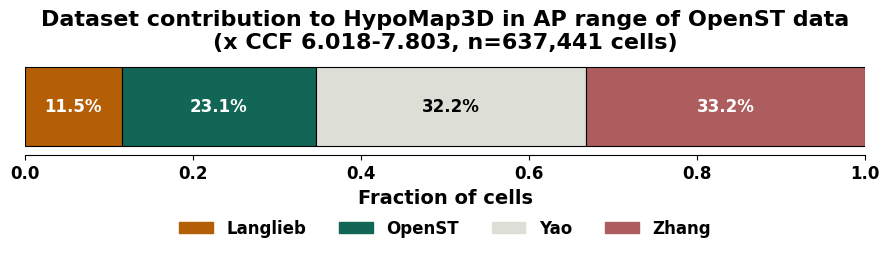

In [236]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ------------------------------------------------------------
# Count and calculate ratios
# ------------------------------------------------------------

author_counts = (
    openstrange["Author"]
    .value_counts()
    .sort_index()   # alphabetical
)

author_ratios = author_counts / author_counts.sum()

# ensure order is alphabetical
authors = sorted(author_ratios.index)

author_ratios = author_ratios.loc[authors]


# ------------------------------------------------------------
# Plot stacked horizontal bar
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 3.5))

left = 0

for author in authors:
    ax.barh(
        y=0,
        width=author_ratios[author],
        left=left,
        color=st_author_colors[author],
        edgecolor="black",
        linewidth=0.8,
        label=author,
    )
    
    # optional percentage labels
    if author_ratios[author] > 0.03:
        ax.text(
            left + author_ratios[author] / 2,
            0,
            f"{author_ratios[author]*100:.1f}%",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white" if author != "Yao" else "black",
        )

    left += author_ratios[author]


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlim(0, 1)
ax.set_ylim(-0.5, 0.5)

ax.set_xlabel(
    "Fraction of cells",
    fontsize=14,
    fontweight="bold",
)

ax.set_yticks([])
ax.tick_params(axis="x", labelsize=12)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

ax.set_title(
    f"Dataset contribution to HypoMap3D in AP range of OpenST data\n(x CCF {round(openst_xccf_min, 3)}-{round(openst_xccf_max, 3)}, n={len(openstrange):,} cells)",
    fontsize=16,
    fontweight="bold",
)

# legend
handles = [
    mpatches.Patch(
        color=st_author_colors[a],
        label=a
    )
    for a in authors
]

legend = ax.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.5),
    ncol=len(authors),
    frameon=False,
    fontsize=12,
)

for text in legend.get_texts():
    text.set_fontweight("bold")

sns.despine(ax=ax, left=True)

plt.tight_layout()

plt.savefig(
    OUTDIR / "openstrange_cell_fraction_by_author.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## author ratios of cell types

In [237]:

# Specify clustering level
level = "L4"

min_num_openst_cells = 0

# Column names
cluster_col = f"{level}_descr_max_p"
prob_col = f"{level}_max_p"

# Keep only confident assignments
filtered = openstrange[openstrange[prob_col] > 0.5].copy()

# Count cells per Author x Cluster
counts = (
    filtered
    .groupby(["Author", cluster_col])
    .size()
    .unstack(fill_value=0)
    .T
)

# Set names
counts.index.name = "Cluster"
counts.columns.name = "Author"

# Calculate fraction of each cluster contributed by each author
ratios_per_cluster = counts.div(counts.sum(axis=1), axis=0)

# Calculate author ratios per cluster
# (fraction of each author's confidently assigned cells belonging to each cluster)
ratios_per_author = counts.div(counts.sum(axis=0), axis=1)

# # Remove empty clusters (if any)
# counts = counts.loc[counts.sum(axis=1) > 0]

# filter for cell types with at least n OpenSt cells 
counts = counts.loc[counts.OpenST >= min_num_openst_cells]
counts["all"] = counts.sum(axis=1)

ratios_per_cluster = ratios_per_cluster.loc[counts.index]
ratios_per_author = ratios_per_author.loc[counts.index]

plot_ratios = ratios_per_cluster.sort_values(by="OpenST", ascending=False).dropna()

/tmp/ipykernel_3473004/3579295464.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_3473004/3579295464.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


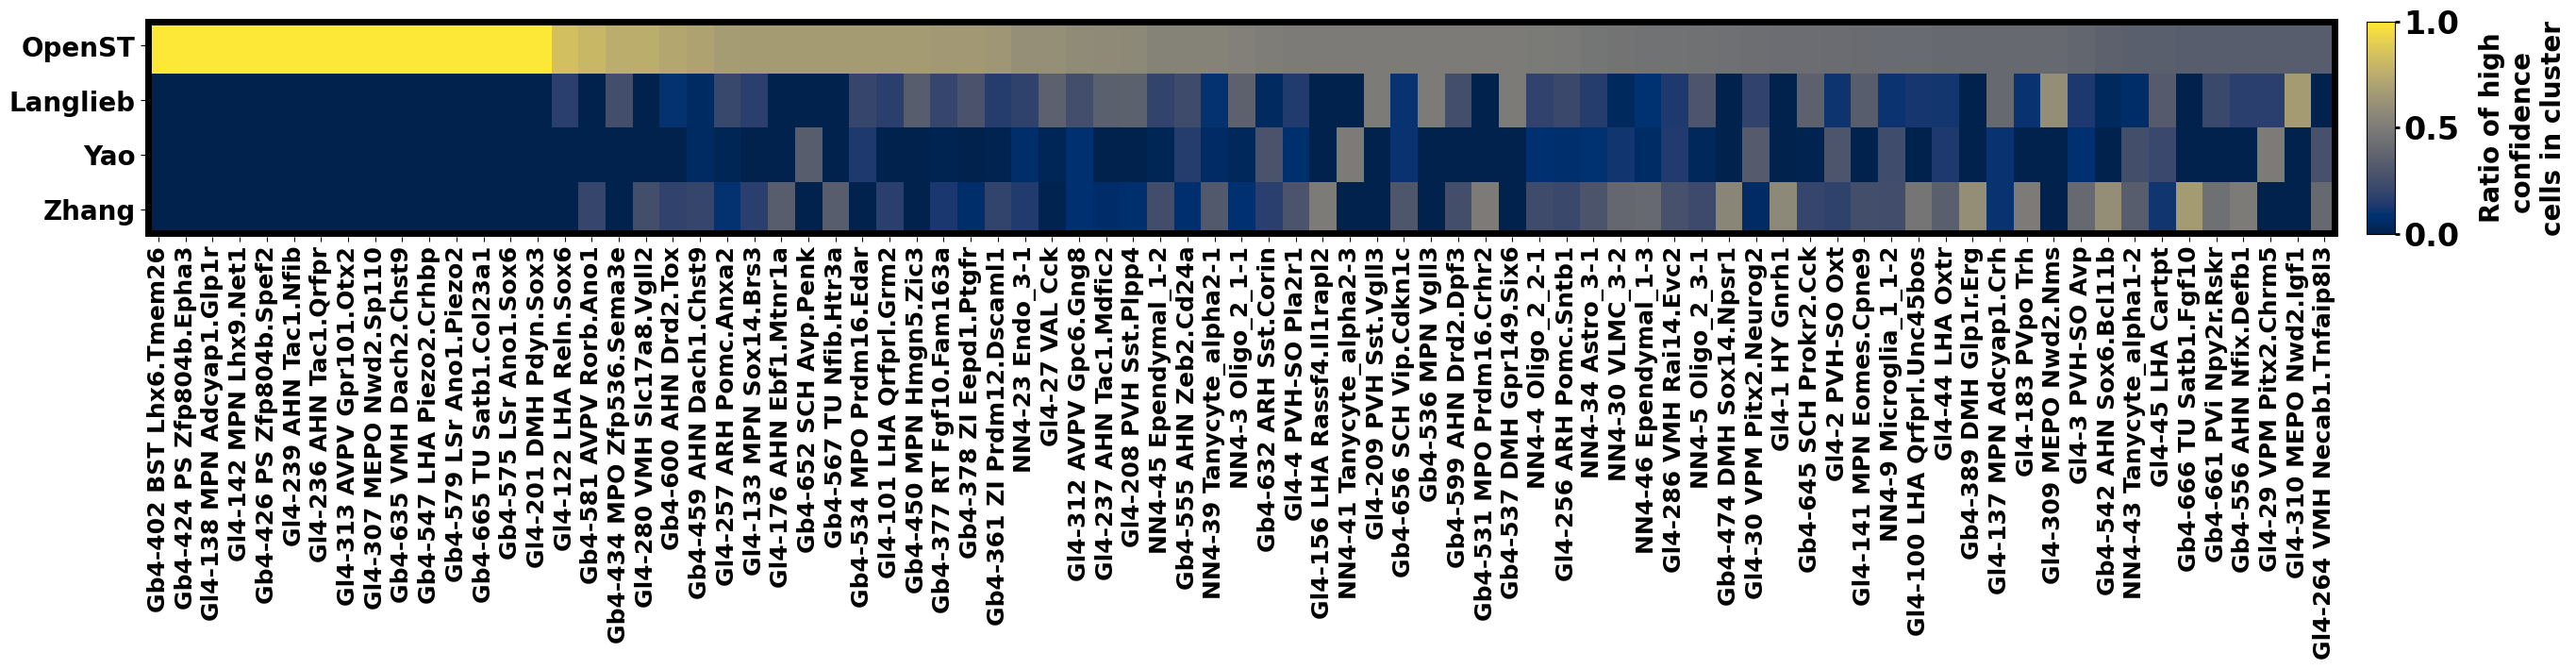

In [249]:
p = 0.33 

# Filter and transpose the data
data = plot_ratios[plot_ratios.OpenST > p].T.values
x_labels = plot_ratios[plot_ratios.OpenST > p].index
y_labels = plot_ratios.columns


# --- Create figure ---
fig, ax = plt.subplots(figsize=(30, 3))  # flipped aspect ratio

# Show the data
im = ax.imshow(data, cmap="cividis", aspect="auto")  # aspect="auto" allows flexible cell sizing

# --- Set tick labels ---
ax.set_xticks(np.arange(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=90, ha="center", fontsize=18, fontweight="bold")

ax.set_yticks(np.arange(len(y_labels)))
ax.set_yticklabels(y_labels, fontsize=20, fontweight="bold")

# --- Remove spines and grid ---
ax.set_frame_on(False)

# Optional: add rectangle for OpenST > p
mask = plot_ratios['OpenST'] > p
if mask.any():
    col_positions = np.where(mask)[0]
    x_start = col_positions.min()
    width = len(col_positions)
    height = len(y_labels)
    rect = plt.Rectangle(
        (x_start-0.5, -0.5), width, height, linewidth=10, edgecolor='black', facecolor='none'
    )
    ax.add_patch(rect)


# --- Custom colorbar ---
# Adjust the figure coordinates: [x0, y0, width, height]
cbar_ax = fig.add_axes([0.91, 0.12, 0.01, 0.75])  

norm = mpl.colors.Normalize(vmin=plot_ratios.values.min(), vmax=plot_ratios.values.max())
sm = mpl.cm.ScalarMappable(cmap="cividis", norm=norm)
cbar = fig.colorbar(sm, cax=cbar_ax)

cbar.set_label("Ratio of high\nconfidence \ncells in cluster", fontsize=20, fontweight="bold", labelpad=15)
cbar.ax.tick_params(labelsize=24, width=2)
for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight("bold")


plt.tight_layout()
plt.savefig(OUTDIR / f"high_conf_cells_{level}_zoom.pdf", dpi=300, bbox_inches='tight')
plt.show()

# Plotting spatial slices 

In [250]:

from matplotlib.ticker import MaxNLocator

def plot_spatial_slice(
    adata,
    x_ccf_value,
    color_by=None,
    cmap='viridis',
    point_size=0.05,
    alpha=1,
    figsize=(5, 5),
    vmin=None,
    vmax=None,
    xlim=None,
    ylim=None,
    save_dir=None,
    x_tolerance=1e-3, 
    category_colors=None,
    bottom_category=None,      
):
    """
    Plot a spatial slice from an AnnData object for a given x_ccf coordinate.
    """

    # --- Subset the data by x_ccf ---
    mask = np.isclose(adata.obs['x_ccf'], x_ccf_value, atol=x_tolerance)
    obs_slice = adata.obs[mask]
    if obs_slice.empty:
        print(f"No cells found for x_ccf = {x_ccf_value} (tol={x_tolerance})")
        return

    idx = obs_slice.index

    # --- Color selection logic ---
    categorical = False

    if color_by is not None:
        if color_by in obs_slice.columns:
            vals = obs_slice[color_by]

            # Detect categorical
            if pd.api.types.is_categorical_dtype(vals) or vals.dtype == object:
                categorical = True
                unique_cats = vals.astype(str).unique()

                # ---- NEW BEHAVIOR: If category_colors is provided, use it ----
                if category_colors is not None:
                    # ensure all categories get a color
                    missing = [c for c in unique_cats if c not in category_colors]
                    if missing:
                        raise ValueError(
                            f"Missing colors for categories: {missing}\n"
                            f"Provide colors for all categories in category_colors."
                        )
                    color_map = {cat: category_colors[cat] for cat in unique_cats}

                else:
                    # default seaborn palette
                    palette = sns.color_palette("tab20", n_colors=len(unique_cats))
                    color_map = dict(zip(unique_cats, palette))

                colors = pd.Series(vals.astype(str)).map(color_map)

            else:
                colors = vals.values

        elif color_by in adata.var_names:
            gene_exp = adata[idx, color_by].X
            if sp.issparse(gene_exp):
                gene_exp = gene_exp.toarray().flatten()
            else:
                gene_exp = np.array(gene_exp).flatten()
            colors = gene_exp

        else:
            raise ValueError(
                f"'{color_by}' not found in adata.obs columns or adata.var_names."
            )
    else:
        colors = '#116656'

    # --- Plot ---
    plt.figure(figsize=figsize)

    if categorical and bottom_category is not None:

        # cells belonging to the category that should be in the background
        bottom_mask = vals.astype(str) == str(bottom_category)

        # plot background category first
        plt.scatter(
            -obs_slice.loc[bottom_mask, "z_ccf"],
            -obs_slice.loc[bottom_mask, "y_ccf"],
            c=colors[bottom_mask],
            s=point_size,
            alpha=alpha,
            linewidths=0,
        )

        # plot all remaining cells afterwards
        plt.scatter(
            -obs_slice.loc[~bottom_mask, "z_ccf"],
            -obs_slice.loc[~bottom_mask, "y_ccf"],
            c=colors[~bottom_mask],
            s=point_size,
            alpha=alpha,
            linewidths=0,
        )

        sc = None

    else:

        sc = plt.scatter(
            -obs_slice["z_ccf"],
            -obs_slice["y_ccf"],
            c=colors,
            cmap=cmap if not categorical else None,
            s=point_size,
            alpha=alpha,
            vmin=vmin,
            vmax=vmax,
            linewidths=0,
        )

    # --- Legend or colorbar ---
    if color_by is not None:
        if categorical:

            # --- Sort categories alphabetically ---
            sorted_cats = sorted(unique_cats)

            # --- Create handles in sorted order ---
            handles = [
                plt.Line2D(
                    [0], [0], marker='o', color='w',
                    label=str(cat),
                    markerfacecolor=color_map[cat],
                    markersize=8,
                    alpha=alpha
                )
                for cat in sorted_cats
            ]

            # --- Create the legend ---
            leg = plt.legend(
                handles=handles,
                title=color_by,
                bbox_to_anchor=(1.05, 1),
                loc='upper left',
                frameon=False
            )

            # --- Make legend bold ---
            plt.setp(leg.get_texts(), fontweight='bold')
            if leg.get_title() is not None:
                leg.get_title().set_fontweight('bold')

        else:
            cbar = plt.colorbar(sc)
            cbar.set_label(color_by, fontsize=20, fontweight='bold', labelpad=15)
            cbar.ax.tick_params(labelsize=20, width=1.5)
            cbar.locator = MaxNLocator(nbins=5)
            cbar.update_ticks()
            for tick in cbar.ax.get_yticklabels():
                tick.set_fontweight('bold')

    # --- Aesthetics ---
    plt.title(f"Slice at x CCF = {x_ccf_value:.3f} mm", fontsize=16, fontweight='bold')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.axis('equal')
    plt.box(False)

    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)

    plt.xticks([])
    plt.yticks([])
    plt.tick_params(bottom=False, left=False)
    plt.tight_layout()

    # --- Save ---
    if save_dir:
        filename = f"{color_by or 'default'}_{x_ccf_value:.3f}.pdf"
        save_path = Path(save_dir) / filename
        plt.savefig(save_path, dpi=300, bbox_inches='tight', format="pdf")
        print(f"Saved plot to {save_path}")


In [251]:
openst_filtered = openst[~openst.obs.GetsHvgFiltered].copy()

In [252]:
openst_filtered.layers["raw"] = openst_filtered.X.copy()
sc.pp.normalize_total(openst_filtered, target_sum = 10_000) 
sc.pp.log1p(openst_filtered)

In [253]:
openst_filtered.obs["-y_ccf"] = - openst_filtered.obs["y_ccf"] # for plotting convenience
openst_filtered.obs["-z_ccf"] = - openst_filtered.obs["z_ccf"]

for i in range(1,6):
    openst_filtered.obs[f"L{i}_ID_max_p"] = openst_filtered.obs[f"L{i}_descr_max_p"].apply(lambda x: x.split(" ")[0])

In [254]:
openst_filtered.obs.columns

Index(['Dataset', 'Sample', 'Author', 'Technology', 'Donor', 'Sex', 'RegionID',
       'RegionAcronym', 'RegionName', 'L1_descr_max_p', 'L1_abc_like_max_p',
       'L1_max_p', 'L2_descr_max_p', 'L2_abc_like_max_p', 'L2_max_p',
       'L3_descr_max_p', 'L3_abc_like_max_p', 'L3_max_p', 'L4_descr_max_p',
       'L4_abc_like_max_p', 'L4_max_p', 'L5_descr_max_p', 'L5_abc_like_max_p',
       'L5_max_p', 'total_counts', 'total_hvg_counts', 'total_genes',
       'GetsHvgFiltered', 'IsInsideBbox', 'x_ccf', 'y_ccf', 'z_ccf',
       'n_genes_by_counts', 'reads_per_counts', '-y_ccf', '-z_ccf',
       'L1_ID_max_p', 'L2_ID_max_p', 'L3_ID_max_p', 'L4_ID_max_p',
       'L5_ID_max_p'],
      dtype='object')

## Plotting high confidence cells 

In [255]:
def get_high_confidence_cells(adata, level, clusters_to_binarize, col_to_add, min_p = 0.5):
    adata.obs[col_to_add] = "other"

    binarize_mask = (
        adata.obs[f"{level}_ID_max_p"].isin(clusters_to_binarize)) & (
        adata.obs[f"{level}_max_p"] > min_p
        )

    adata.obs.loc[binarize_mask, col_to_add] = adata.obs.loc[binarize_mask, f"{level}_descr_max_p"]


In [256]:
level = "L4"

clusters_to_binarize = [
    # PVH
    "Gl4-4", # PVH-SO Pla2r1
    #"Gl4-209", # PVH Sst.Vgll3
    "Gl4-2", # "PVH-SO Oxt"
    #"Gl4-208", # PVH Sst.Plpp4

    # Tany
    #"NN4-41", #alpha2-3
    "NN4-43", # alpha1-2
    #"NN4-39", # alpha2-1

    # Ependymal
    #"NN4-46", # 1-3
    "NN4-45", # 1-2

    # Pmch, aka Cartpt cluster
    "Gl4-45", # LHA Cartpt

    "Gl4-44", # LHA Oxtr

    # Pomc
    "Gl4-256", # Pomc.Sntb1
    "Gl4-257", # Pomc.Anxa2
    
]

col_to_add = "openst_specific"

get_high_confidence_cells(openst_filtered, level, clusters_to_binarize, col_to_add, min_p = 0.5)

In [257]:

color_map = {
    "other": "lightgrey",
    "Gl4-4 PVH-SO Pla2r1": "blue", 
    "Gl4-2 PVH-SO Oxt": "purple", 
    "NN4-43 Tanycyte_alpha1-2": "red", 
    #"NN4-39 Tanycyte_alpha2-1": "chartreuse", 
    #"NN4-46 Ependymal_1-3": "black",
    "NN4-45 Ependymal_1-2": "black",
    "Gl4-45 LHA Cartpt": "brown",
    "Gl4-256 ARH Pomc.Sntb1": "orange", 
    "Gl4-257 ARH Pomc.Anxa2": "cyan",
    "Gl4-44 LHA Oxtr": "green",


}

In [258]:
indices = [0,6, 10]

/tmp/ipykernel_3473004/87327562.py:41: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vals) or vals.dtype == object:
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


6.018229007720947


/tmp/ipykernel_3473004/87327562.py:41: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vals) or vals.dtype == object:
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Saved plot to /REDACTED-path/HypoMap3D-data/v0.9/publication/Ext_Fig_02/openst_specific_6.018.pdf
6.655652046203613


/tmp/ipykernel_3473004/87327562.py:41: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vals) or vals.dtype == object:
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Saved plot to /REDACTED-path/HypoMap3D-data/v0.9/publication/Ext_Fig_02/openst_specific_6.656.pdf
7.109816074371338
Saved plot to /REDACTED-path/HypoMap3D-data/v0.9/publication/Ext_Fig_02/openst_specific_7.110.pdf


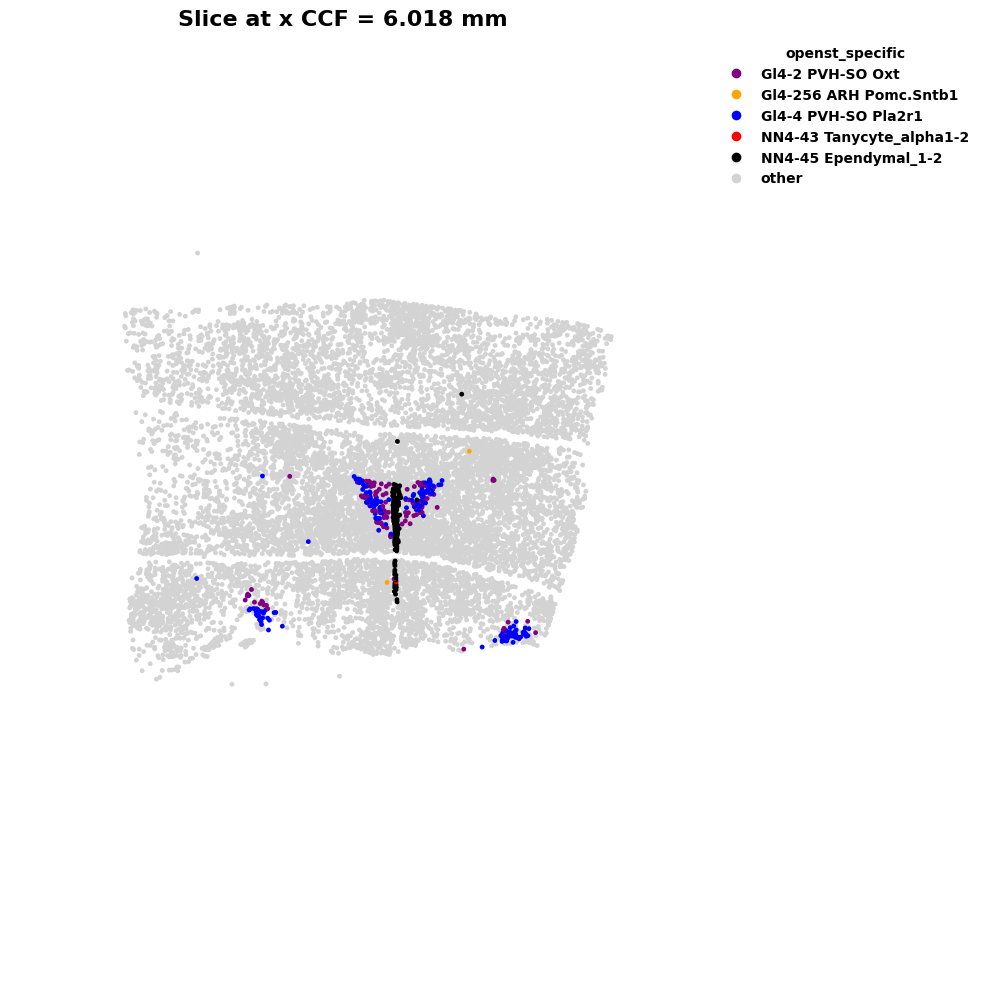

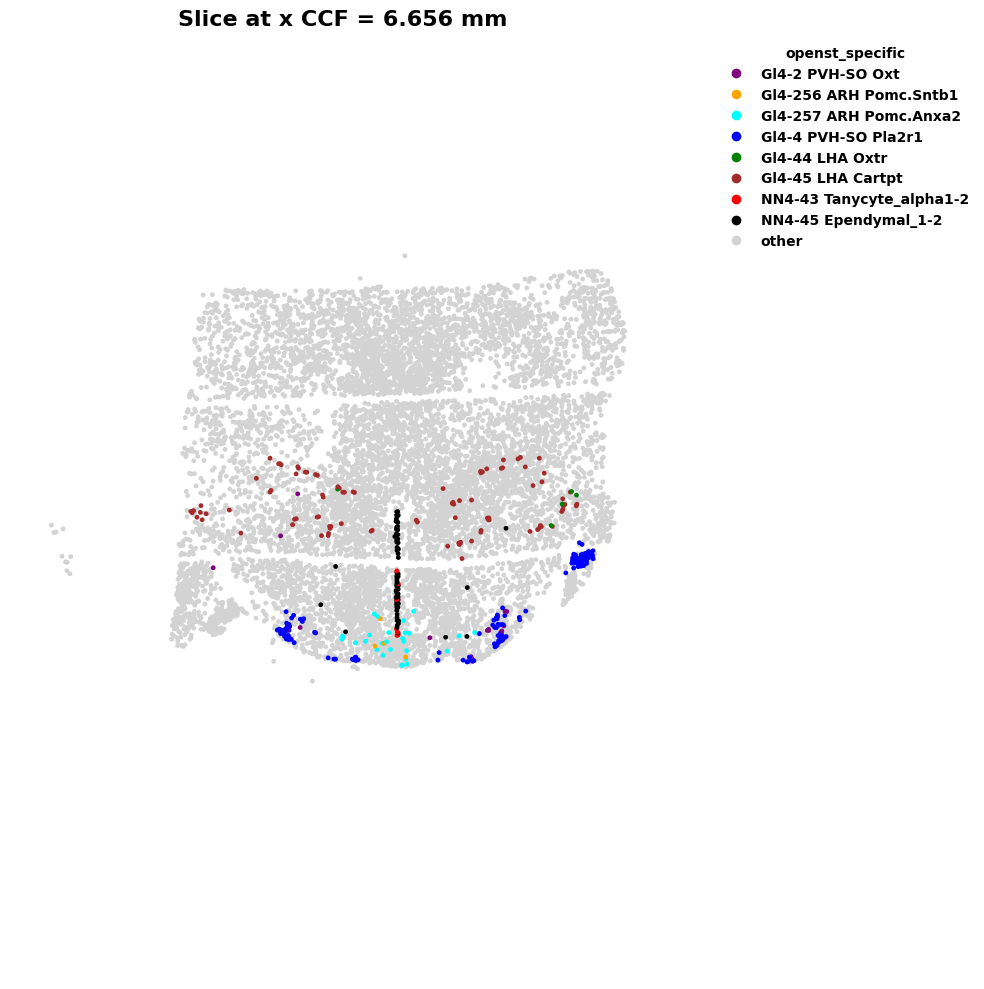

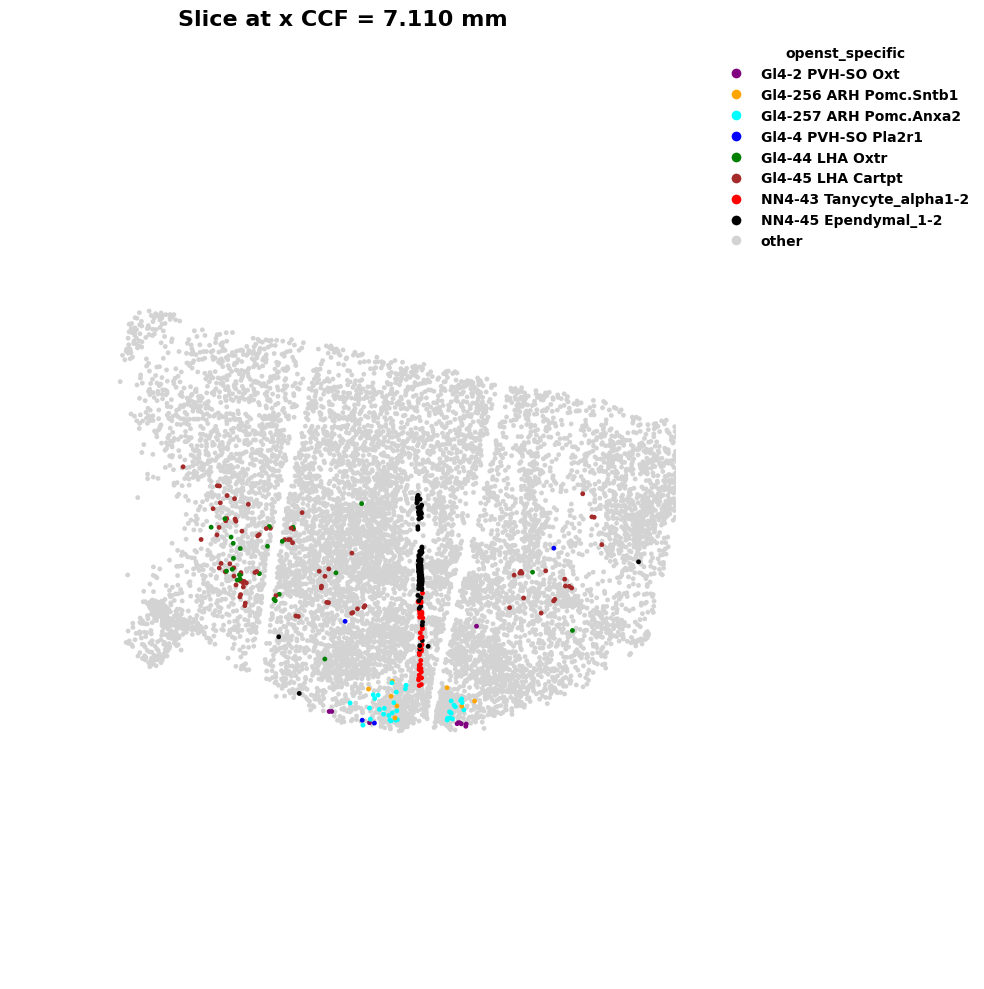

In [259]:
color_by = "openst_specific"


# Get the unique x_ccf coordinates in sorted order
x_coords = np.sort(openst_filtered.obs['x_ccf'].unique())

for i, ccf in enumerate(x_coords):
    if  i in indices:
    #if True:
        print(ccf)

        plot_spatial_slice(
            openst_filtered,
            x_ccf_value = ccf,
            color_by=color_by,
            cmap='viridis',
            point_size=12,
            alpha=1,
            figsize=(10, 10),
            vmin=0,
            vmax=7,
            xlim = (-9.5, - 3),
            ylim = (-9.5, - 2),
            save_dir = OUTDIR,
            category_colors=color_map,
            bottom_category="other"
        )

## plot GE

In [260]:
from pathlib import Path

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import MaxNLocator
from matplotlib import colormaps


def plot_spatial_three_gene_max(
    adata,
    genes,
    x_ccf_values,
    cmaps,
    point_size=0.05,
    alpha=1,
    background_color="lightgrey",
    background_alpha=0.35,
    figsize=(12, 4),
    x_tolerance=1e-3,
    xlim=None,
    ylim=None,
    save_dir=None,
):
    """
    Plot three spatial slices. Cells are colored according to the
    maximally expressed gene among the supplied genes.

    Parameters
    ----------
    genes : list of str (length=3)
        Gene names.

    x_ccf_values : list of float (length=3)
        Slice coordinates.

    cmaps : list
        Three matplotlib colormaps.
    """

    assert len(genes) == 3
    assert len(x_ccf_values) == 3
    assert len(cmaps) == 3

    cmaps = [
        colormaps[c] if isinstance(c, str) else c
        for c in cmaps
    ]

    # ---------------------------------------------------------
    # Compute shared vmax for each gene
    # ---------------------------------------------------------

    vmaxs = []

    for gene in genes:

        expr = adata[:, gene].X

        if sp.issparse(expr):
            expr = expr.toarray().ravel()
        else:
            expr = np.asarray(expr).ravel()

        vmaxs.append(expr.max())

    vmins = [0] * 3

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=figsize,
        sharex=True,
        sharey=True,
        gridspec_kw={"wspace": 0.02}   # default is ~0.2
    )

    # ---------------------------------------------------------
    # Loop over slices
    # ---------------------------------------------------------

    for ax, x_ccf in zip(axes, x_ccf_values):

        mask = np.isclose(
            adata.obs["x_ccf"],
            x_ccf,
            atol=x_tolerance,
        )

        obs = adata.obs.loc[mask]

        if len(obs) == 0:
            continue

        idx = obs.index

        # -------------------------
        # Extract expression
        # -------------------------

        exprs = []

        for gene in genes:

            x = adata[idx, gene].X

            if sp.issparse(x):
                x = x.toarray().ravel()
            else:
                x = np.asarray(x).ravel()

            exprs.append(x)

        exprs = np.vstack(exprs)          # (3, n_cells)

        winner = np.argmax(exprs, axis=0)

        max_expr = exprs.max(axis=0)

        # -------------------------
        # Background
        # -------------------------

        ax.scatter(
            -obs["z_ccf"],
            -obs["y_ccf"],
            color=background_color,
            s=point_size,
            alpha=background_alpha,
            linewidths=0,
        )

        # -------------------------
        # Plot each winner separately
        # -------------------------

        for g in range(3):

            keep = (winner == g) & (max_expr > 0)

            if not np.any(keep):
                continue

            vals = exprs[g, keep]

            norm = Normalize(
                vmin=vmins[g],
                vmax=vmaxs[g],
            )

            colors = cmaps[g](norm(vals))

            ax.scatter(
                -obs["z_ccf"].values[keep],
                -obs["y_ccf"].values[keep],
                color=colors,
                s=point_size,
                alpha=alpha,
                linewidths=0,
            )

        ax.set_title(
            f"x = {x_ccf:.3f} mm",
            fontsize=16,
            fontweight="bold",
        )

        ax.set_aspect("equal")

        if xlim is not None:
            ax.set_xlim(xlim)

        if ylim is not None:
            ax.set_ylim(ylim)

        ax.set_xticks([])
        ax.set_yticks([])

        ax.set_frame_on(False)

    # ---------------------------------------------------------
    # Three shared colorbars
    # ---------------------------------------------------------
    # Leave space on the right
    fig.subplots_adjust(right=0.82)

    # Horizontal positions for the three colorbars
    cbar_width = 0.01
    cbar_height = 0.30
    bottom = 0.3

    lefts = [0.80, 0.87, 0.94]

    for g in range(3):

        cax = fig.add_axes([
            lefts[g],      # left
            bottom,        # bottom
            cbar_width,    # width
            cbar_height    # height
        ])

        sm = plt.cm.ScalarMappable(
            cmap=cmaps[g],
            norm=Normalize(vmin=vmins[g], vmax=vmaxs[g])
        )
        sm.set_array([])

        cbar = fig.colorbar(sm, cax=cax)

        cbar.set_label(
            genes[g],
            fontsize=14,
            fontweight="bold",
            labelpad=10,
        )

        cbar.ax.tick_params(labelsize=12)

        for tick in cbar.ax.get_yticklabels():
            tick.set_fontweight("bold")

    if save_dir is not None:

        filename = "_".join(genes) + "_max_expression.pdf"

        fig.savefig(
            Path(save_dir) / filename,
            dpi=300,
            bbox_inches="tight",
            format="pdf",
        )

    plt.show()

In [261]:
indices = [1,7,15]
x_coords = np.sort(openst_filtered.obs['x_ccf'].unique())
ccfs = []
for i, ccf in enumerate(x_coords):
    if i in indices:
        ccfs.append(ccf)

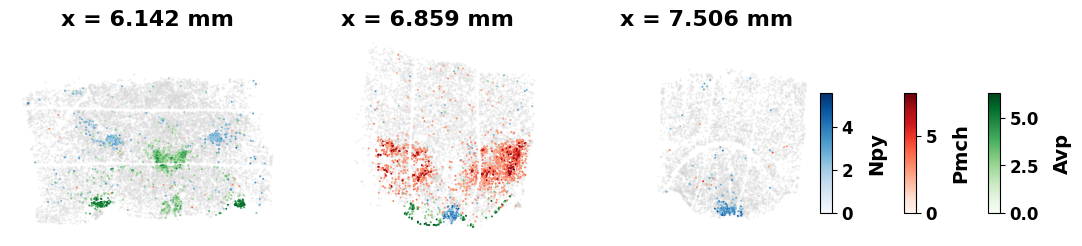

In [263]:
plot_spatial_three_gene_max(
    adata=openst_filtered,
    genes=["Npy", "Pmch", "Avp"],
    x_ccf_values=ccfs,
    cmaps=["Blues", "Reds", "Greens"],
    point_size=2,
    alpha=1,
    background_color="lightgrey",
    background_alpha=0.35,
    figsize=(12, 4),
    x_tolerance=1e-3,
    xlim=None,
    ylim=None,
    save_dir=OUTDIR,
)

In [153]:
ccfs

[np.float64(6.141870021820068),
 np.float64(6.859495162963867),
 np.float64(7.505773544311523)]